# EDA: открытый банк ФИПИ и пилот 50 задач

31 октября 2026. Предметная область — вся профильная математика ЕГЭ. Это описательный пилот, а не законченная модель освоения.

**Два разных объёма:** 1148 условий анализируются Python без модели; 50 задач имеют новые разборы основного ассистента в одном общем контексте. Нет независимых повторов, внешнего экспертного ключа и оценки устойчивости. Основные частоты KC рассчитаны по 49 задачам, одна неоднозначная задача показана отдельно.

Сценарий: состав банка → качество и похожие условия → состав выборки → шаги/KC/маршруты → повторения и сочетания → ограничения и польза для тьютора.

Повторный запуск ноутбука **не вызывает модель и не скачивает сайт**. Рецензия и межзадачные соответствия — явные отдельные входы анализа.

In [1]:
from pathlib import Path
import sys, json, csv, html
from IPython.display import display, HTML, Image, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/analyze_fipi50.py').is_file())
sys.path.insert(0, str(root / 'scripts'))
from analyze_fipi50 import analyze, OUT, RUN
summary = analyze()
def table(rows, columns=None, limit=None):
    rows = list(rows)[:limit]
    columns = columns or list(rows[0])
    head = ''.join('<th>'+html.escape(str(c))+'</th>' for c in columns)
    body = ''.join('<tr>'+''.join('<td>'+html.escape(str(r.get(c,'')))+'</td>' for c in columns)+'</tr>' for r in rows)
    display(HTML('<table><tr>'+head+'</tr>'+body+'</table>'))
def rows(name):
    with (OUT/name).open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))
print('Пересчитано без модели:', summary['bank_tasks'], 'условий банка;', summary['pilot_tasks'], 'разборов;', summary['included_primary_n'], 'задач в основных частотах')

Technically valid: 50 / 50


Пересчитано без модели: 1148 условий банка; 50 разборов; 49 задач в основных частотах


## 1. Что представлено в банке

Первый КЭС используется как воспроизводимая группировка. Отдельно сохранены все метки: одна задача может иметь несколько. Коды банка не приравниваются к кодам кодификатора другой редакции. Эти частоты не являются распределением реального экзамена и не доказывают покрытие всех официальных требований.

Показатель,Значение
bank_tasks,1148
bank_primary_codes,26
bank_all_label_codes,29
bank_label_assignments,1707
bank_with_images,286
bank_with_mathml,859
bank_with_source_warnings,1


code,title,bank_primary_n,bank_primary_pct,bank_any_label_n,sample_primary_n
1.1,Натуральные и целые числа. Признаки делимости целых чисел,83,7.23,83,4
1.2,"Рациональные числа. Обыкновенные и десятичные дроби, проценты, бесконечные периодические дроби",40,3.484,74,2
1.3,Арифметический корень натуральной степени. Действия с арифметическими корнями натуральной степени,12,1.045,13,1
1.4,Степень с целым показателем. Степень с рациональным показателем. Свойства степени,8,0.697,8,1
1.5,"Синус, косинус и тангенс числового аргумента. Арксинус, арккосинус, арктангенс числового аргумента",48,4.181,49,2
1.6,Логарифм числа. Десятичные и натуральные логарифмы,10,0.871,13,1
2.1,Целые и дробно-рациональные уравнения,139,12.108,191,4
2.2,Иррациональные уравнения,27,2.352,27,1
2.3,Тригонометрические уравнения,39,3.397,65,2
2.4,Показательные и логарифмические уравнения,47,4.094,76,2


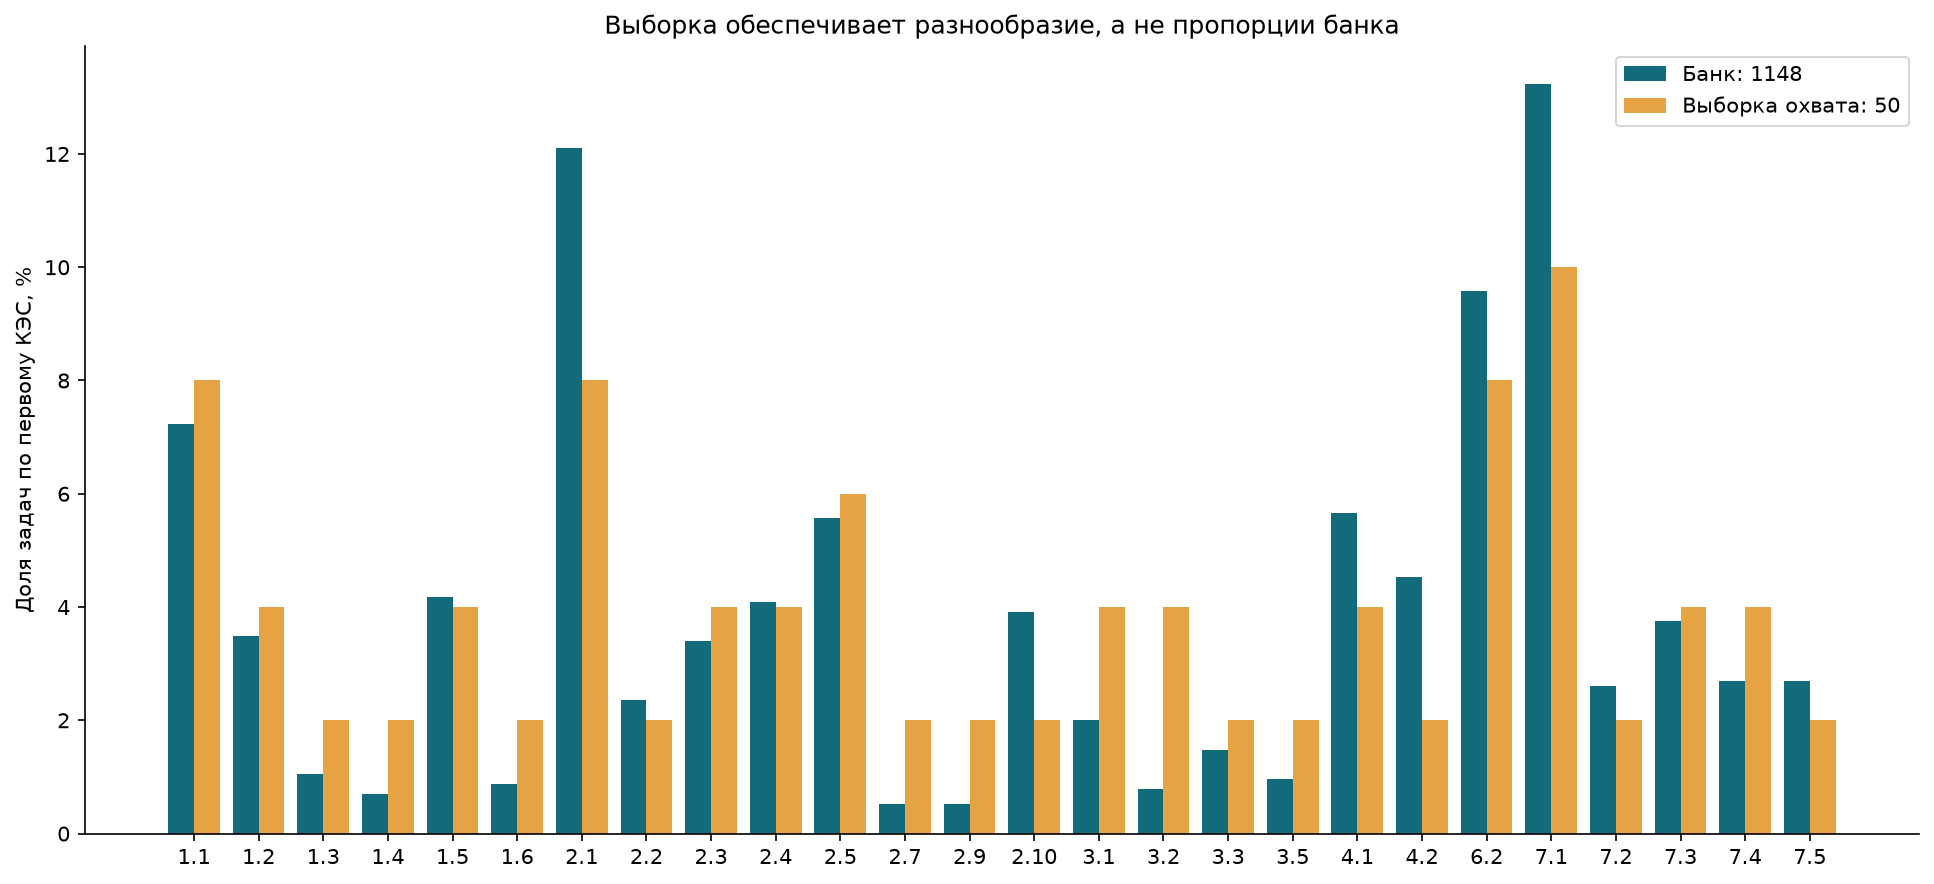

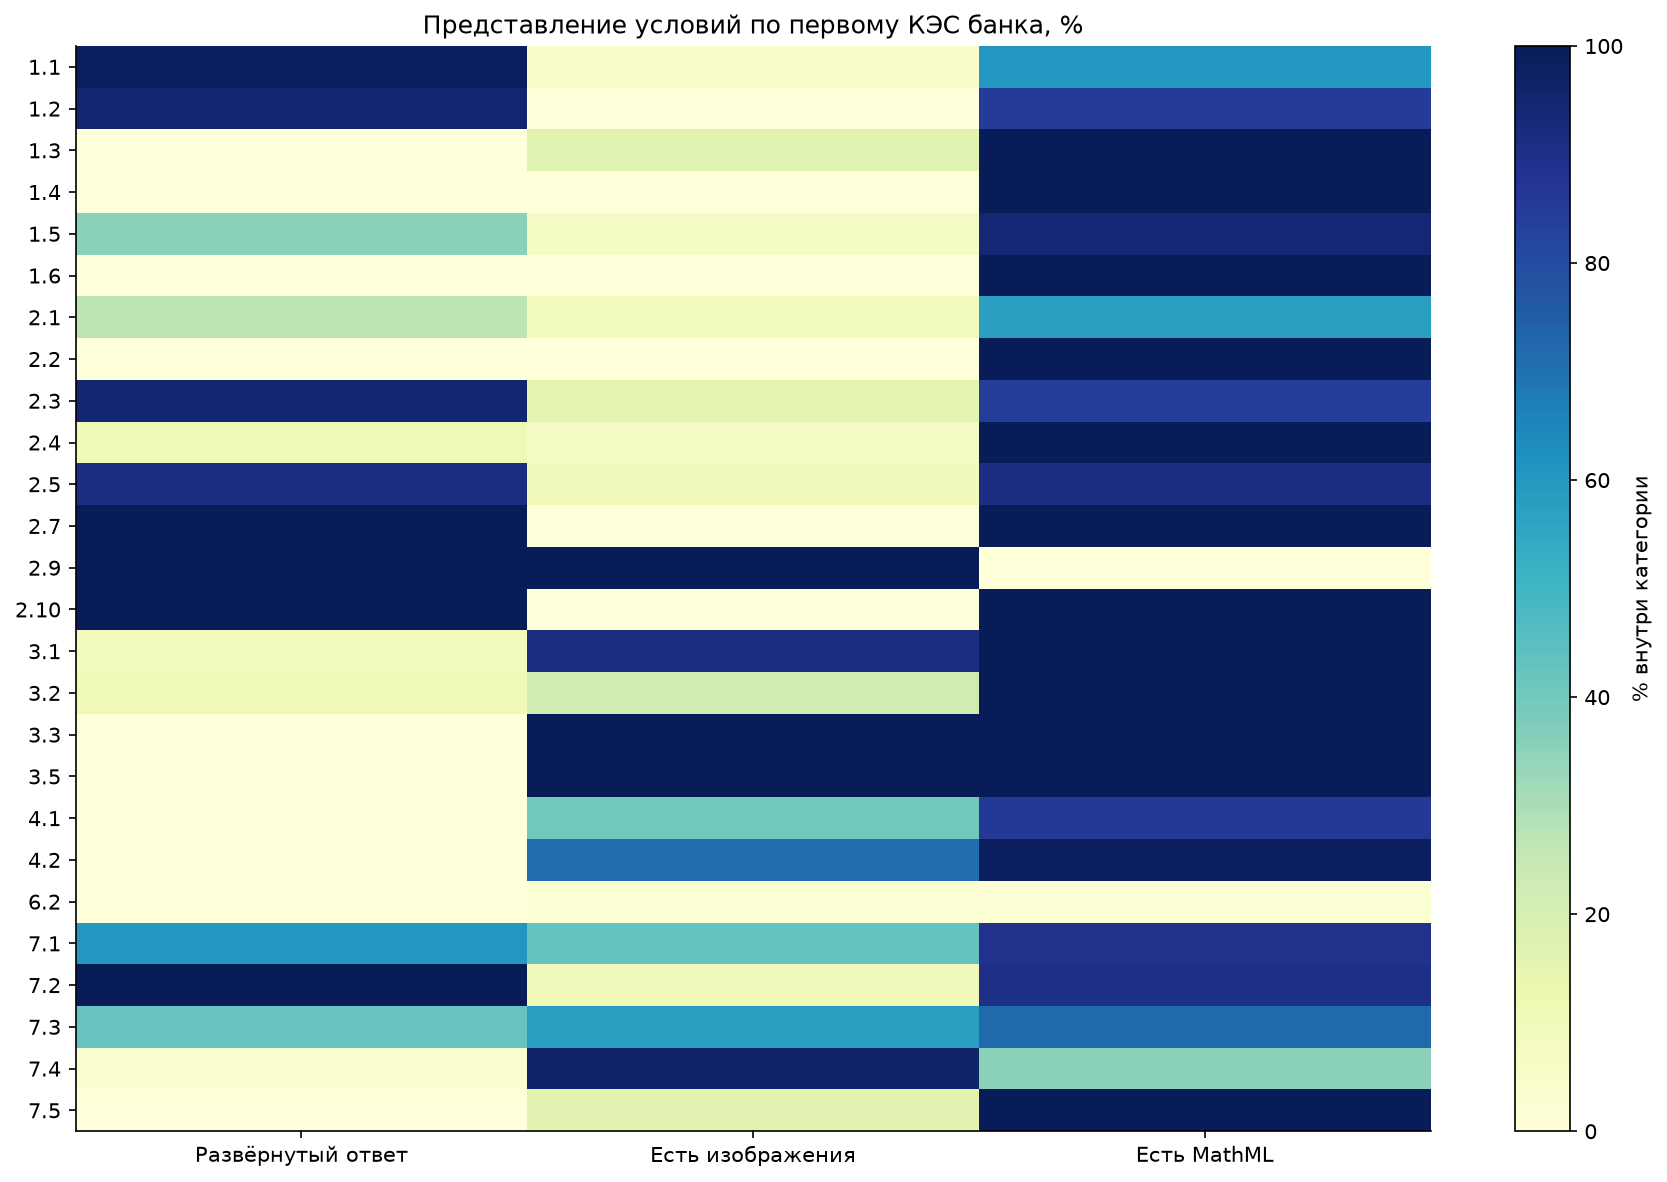

In [2]:
table([{'Показатель':k, 'Значение':summary[k]} for k in ['bank_tasks','bank_primary_codes','bank_all_label_codes','bank_label_assignments','bank_with_images','bank_with_mathml','bank_with_source_warnings']])
table(rows('topics.csv'), ['code','title','bank_primary_n','bank_primary_pct','bank_any_label_n','sample_primary_n'])
display(Image(filename=str(OUT/'01-bank-and-sample.png')))
display(Image(filename=str(OUT/'02-representation.png')))

**Вывод.** Выборка специально даёт примеры редких сочетаний категории и формата, поэтому её доли отличаются от банка. Поддержка смешанных условий обязательна: рисунки и формулы-картинки не заменяются обычным текстом. Баланс упражнений для ученика нельзя выбирать только по количеству задач в банке.

## 2. Повторы и шаблоны

Точное совпадение означает совпадение нормализованного DOM, текста, инструкции и содержимого изображений. Маски чисел создают только кандидатов на похожие шаблоны: смена показателя степени тоже может менять метод. Семейства требуют предметного просмотра до разделения разработки и проверки.

In [3]:
dups = json.loads((OUT/'duplicate-groups.json').read_text(encoding='utf-8'))
print('Групп строгих совпадений:', summary['exact_duplicate_groups'])
print('Кандидатных числовых шаблонов:', summary['template_candidate_groups'])
table([{'Число задач':len(g),'ID':', '.join(g)} for g in dups['numeric_template_candidates'][:8]])

Групп строгих совпадений: 0
Кандидатных числовых шаблонов: 90


Число задач,ID
7,"91D905, D170BF, 9B2D2B, F253DE, 51EADD, 6DBE38, 944788"
6,"0ECDD4, 11CCDE, 8EF0DE, 73B69F, 80A99C, 07D66F"
5,"198c47, 346547, 2AFDA9, 546A68, EBB536"
5,"1c7454, ee1AA2, 58e4c5, 8e0D68, 4A073e"
5,"997E04, 6E7D00, 27C71D, 0F9157, 7FF06A"
4,"2AE241, EA7D2B, 9595A4, BAD790"
4,"55eA0e, 06AF1F, 370eDc, 6976e6"
4,"76A1FD, 9945B8, 223ec5, 8F25eA"


## 3. Выборка и качество разборов

50 задач выбраны до решения: по одному из 38 непустых сочетаний «первый КЭС × тип ответа» плюс 12 мест по размеру страт. Сначала проверены 2 задачи, затем партии по 8. Один подтверждённый дефект символа из сбора заранее исключён.

Разборы — авторская работа основного ассистента; сохранённые инструкции не выдаются за изолированные API-запуски. `solved` означает статус предварительного разбора, а не внешнюю валидацию. Поэтому 49/50 не называется accuracy.

Для `eFF32e` требуется уточнение, исключает ли формулировка K=S. В карточке сохранены контрпример при таком допущении и условное решение при внутреннем K; задача исключена из основных метрик.

Статусы: {'solved': 49, 'partial': 1}
Всего шагов: 162 ; локальных кандидатов KC: 204


order,task_id,primary_kes,response_type,status,included,steps,local_kcs,editorial_kcs,methods,warnings
1,7D21DC,3.1,Краткий ответ,solved,True,4,4,4,1,0
2,B948D4,2.4,Краткий ответ,solved,True,2,2,2,1,0
3,D3C781,6.2,Краткий ответ,solved,True,2,2,2,1,0
4,61C181,1.4,Краткий ответ,solved,True,2,1,1,1,0
5,685C13,2.3,Развернутый ответ,solved,True,4,4,4,1,0
6,262AEA,1.1,Развернутый ответ,solved,True,3,3,3,1,0
7,D3C577,1.2,Развернутый ответ,solved,True,5,4,4,3,0
8,002FC3,1.1,Развернутый ответ,solved,True,5,4,4,3,0
9,DDA73A,3.3,Краткий ответ,solved,True,3,5,5,1,0
10,EE054F,2.1,Развернутый ответ,solved,True,5,6,6,1,0


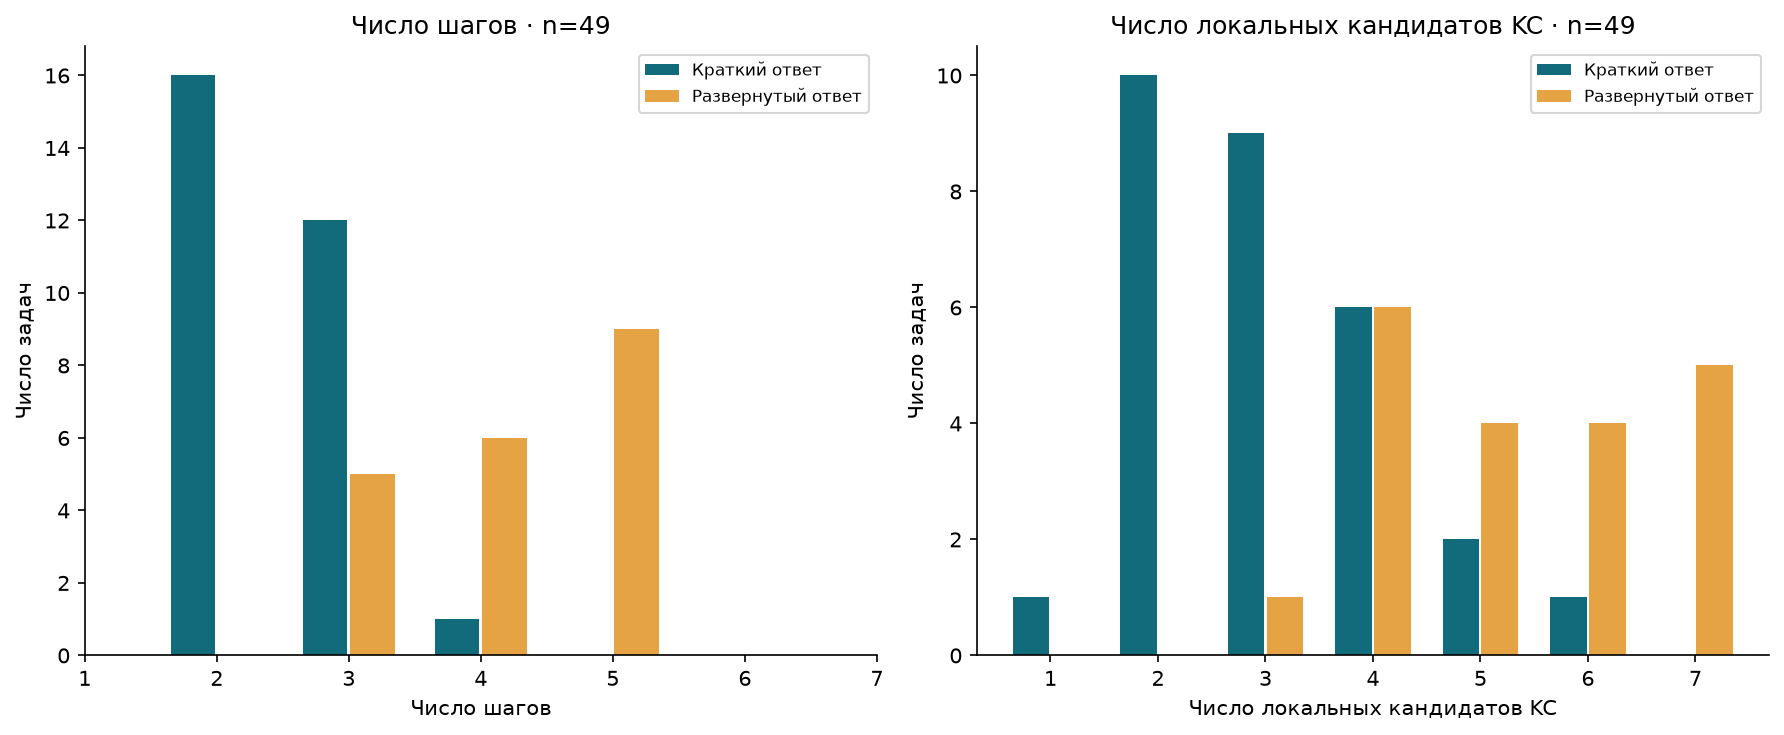

In [4]:
print('Статусы:', summary['status_counts'])
print('Всего шагов:', summary['all_steps'], '; локальных кандидатов KC:', summary['all_local_kcs'])
table(rows('pilot-tasks.csv'))
display(Image(filename=str(OUT/'03-solution-structure.png')))

**Вывод.** Включённые краткие задачи имеют медиану 2 шага и 3 локальных KC, развёрнутые — 4 шага и 5 KC. Это описывает выбранную разметку; не является шкалой сложности. Каждый Method — использованный маршрут или часть решения, не перечень всех возможных методов.

## 4. Межзадачные соответствия и повторяющиеся действия

`catalog-decisions.json` содержит определения, все назначения и цитаты шагов. Явные редакторские группы применены постфактум основным ассистентом. Вне них совпадение требуется и по названию, и по описанию. Старые каталоги и промпты не менялись.

Линейное уравнение, построение уравнения, линейное неравенство и снятие логарифма остаются разными действиями. Восстановление y=kx по одной точке не приравнено к восстановлению y=kx+b по двум точкам.

Показатель,Значение
literal_definition_nodes_included,177
editorial_nodes_included,136
singleton_nodes,101
singleton_fraction,0.7426


kc_id,name,task_n,task_pct
linear_equation,Решать линейное уравнение с числовыми коэффициентами,7,14.286
zero_product,Решать уравнение через нулевое произведение,7,14.286
pythagoras,Находить длину по теореме Пифагора,5,10.204
graph_coordinates,Считывать координаты отмеченной точки с графика,4,8.163
set_intersection,Пересекать множества допустимых значений,4,8.163
graph_intersection,Сводить пересечение графиков к равенству значений,3,6.122
exponential_equation,Сводить показательное уравнение к равенству показателей,3,6.122
classical_probability,Вычислять вероятность по числу равновозможных исходов,3,6.122
elementary_trig_equation,Решать простейшее тригонометрическое уравнение,3,6.122
cosine_law,Применять теорему косинусов,3,6.122


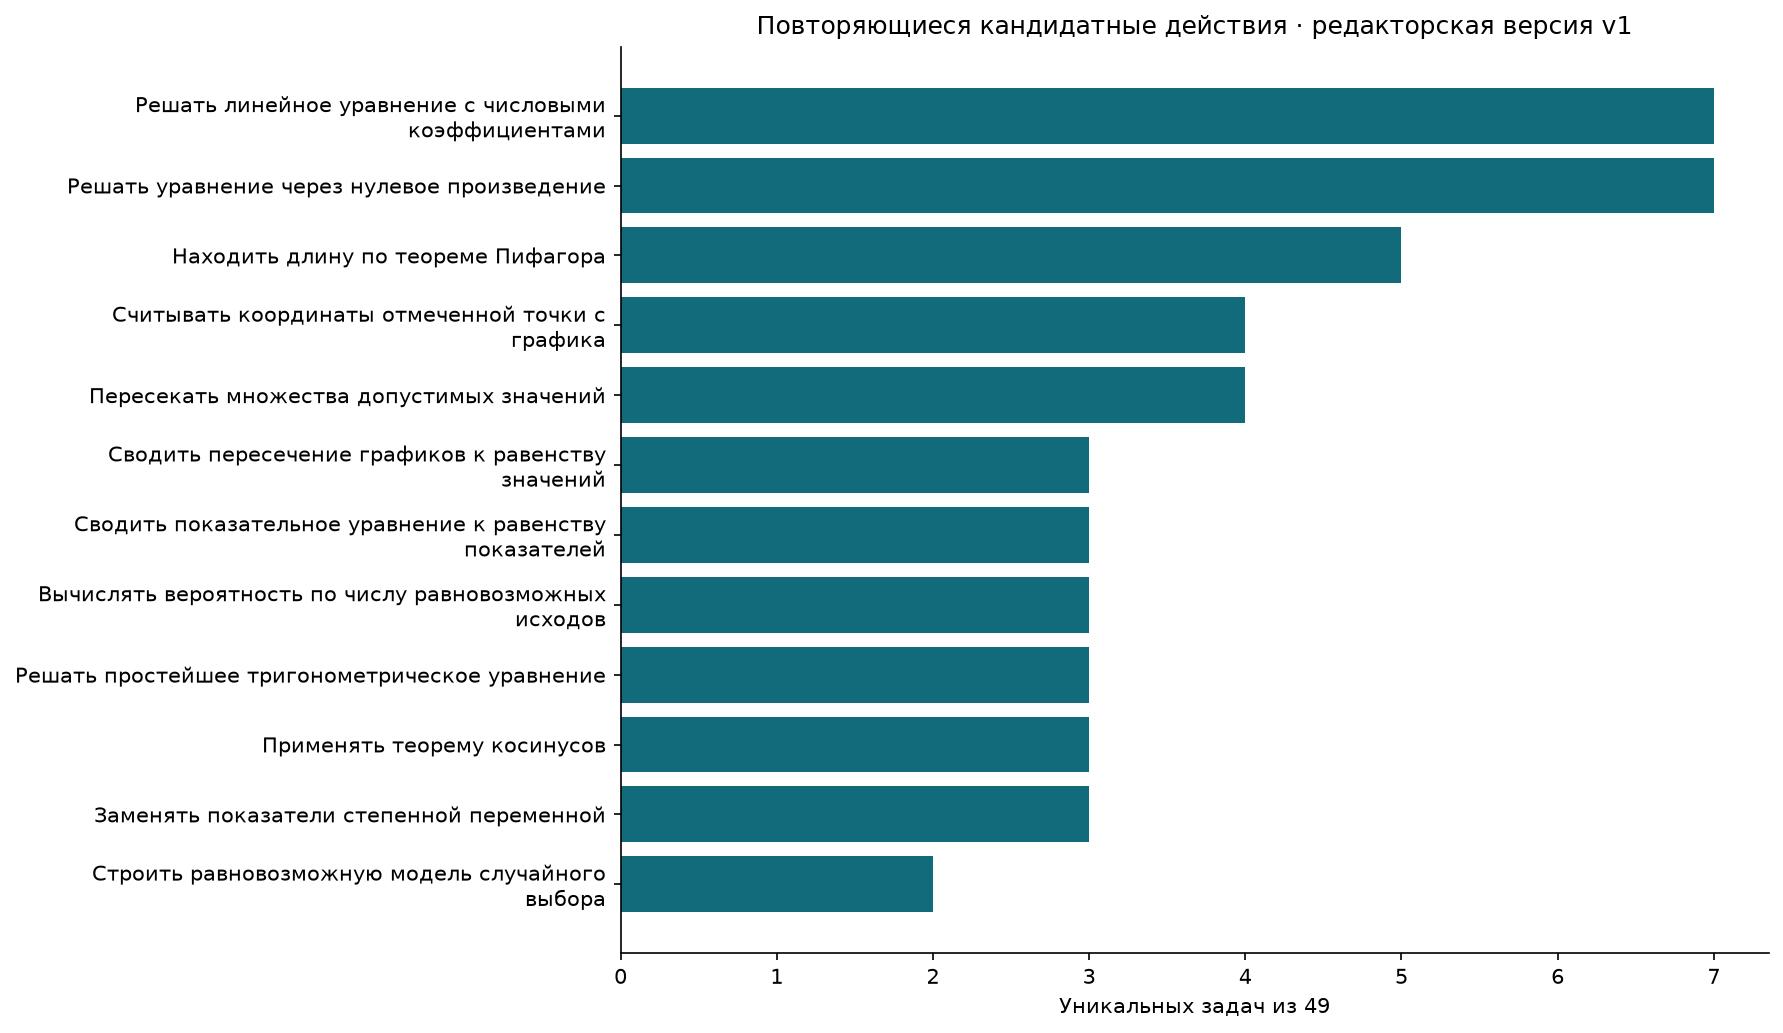

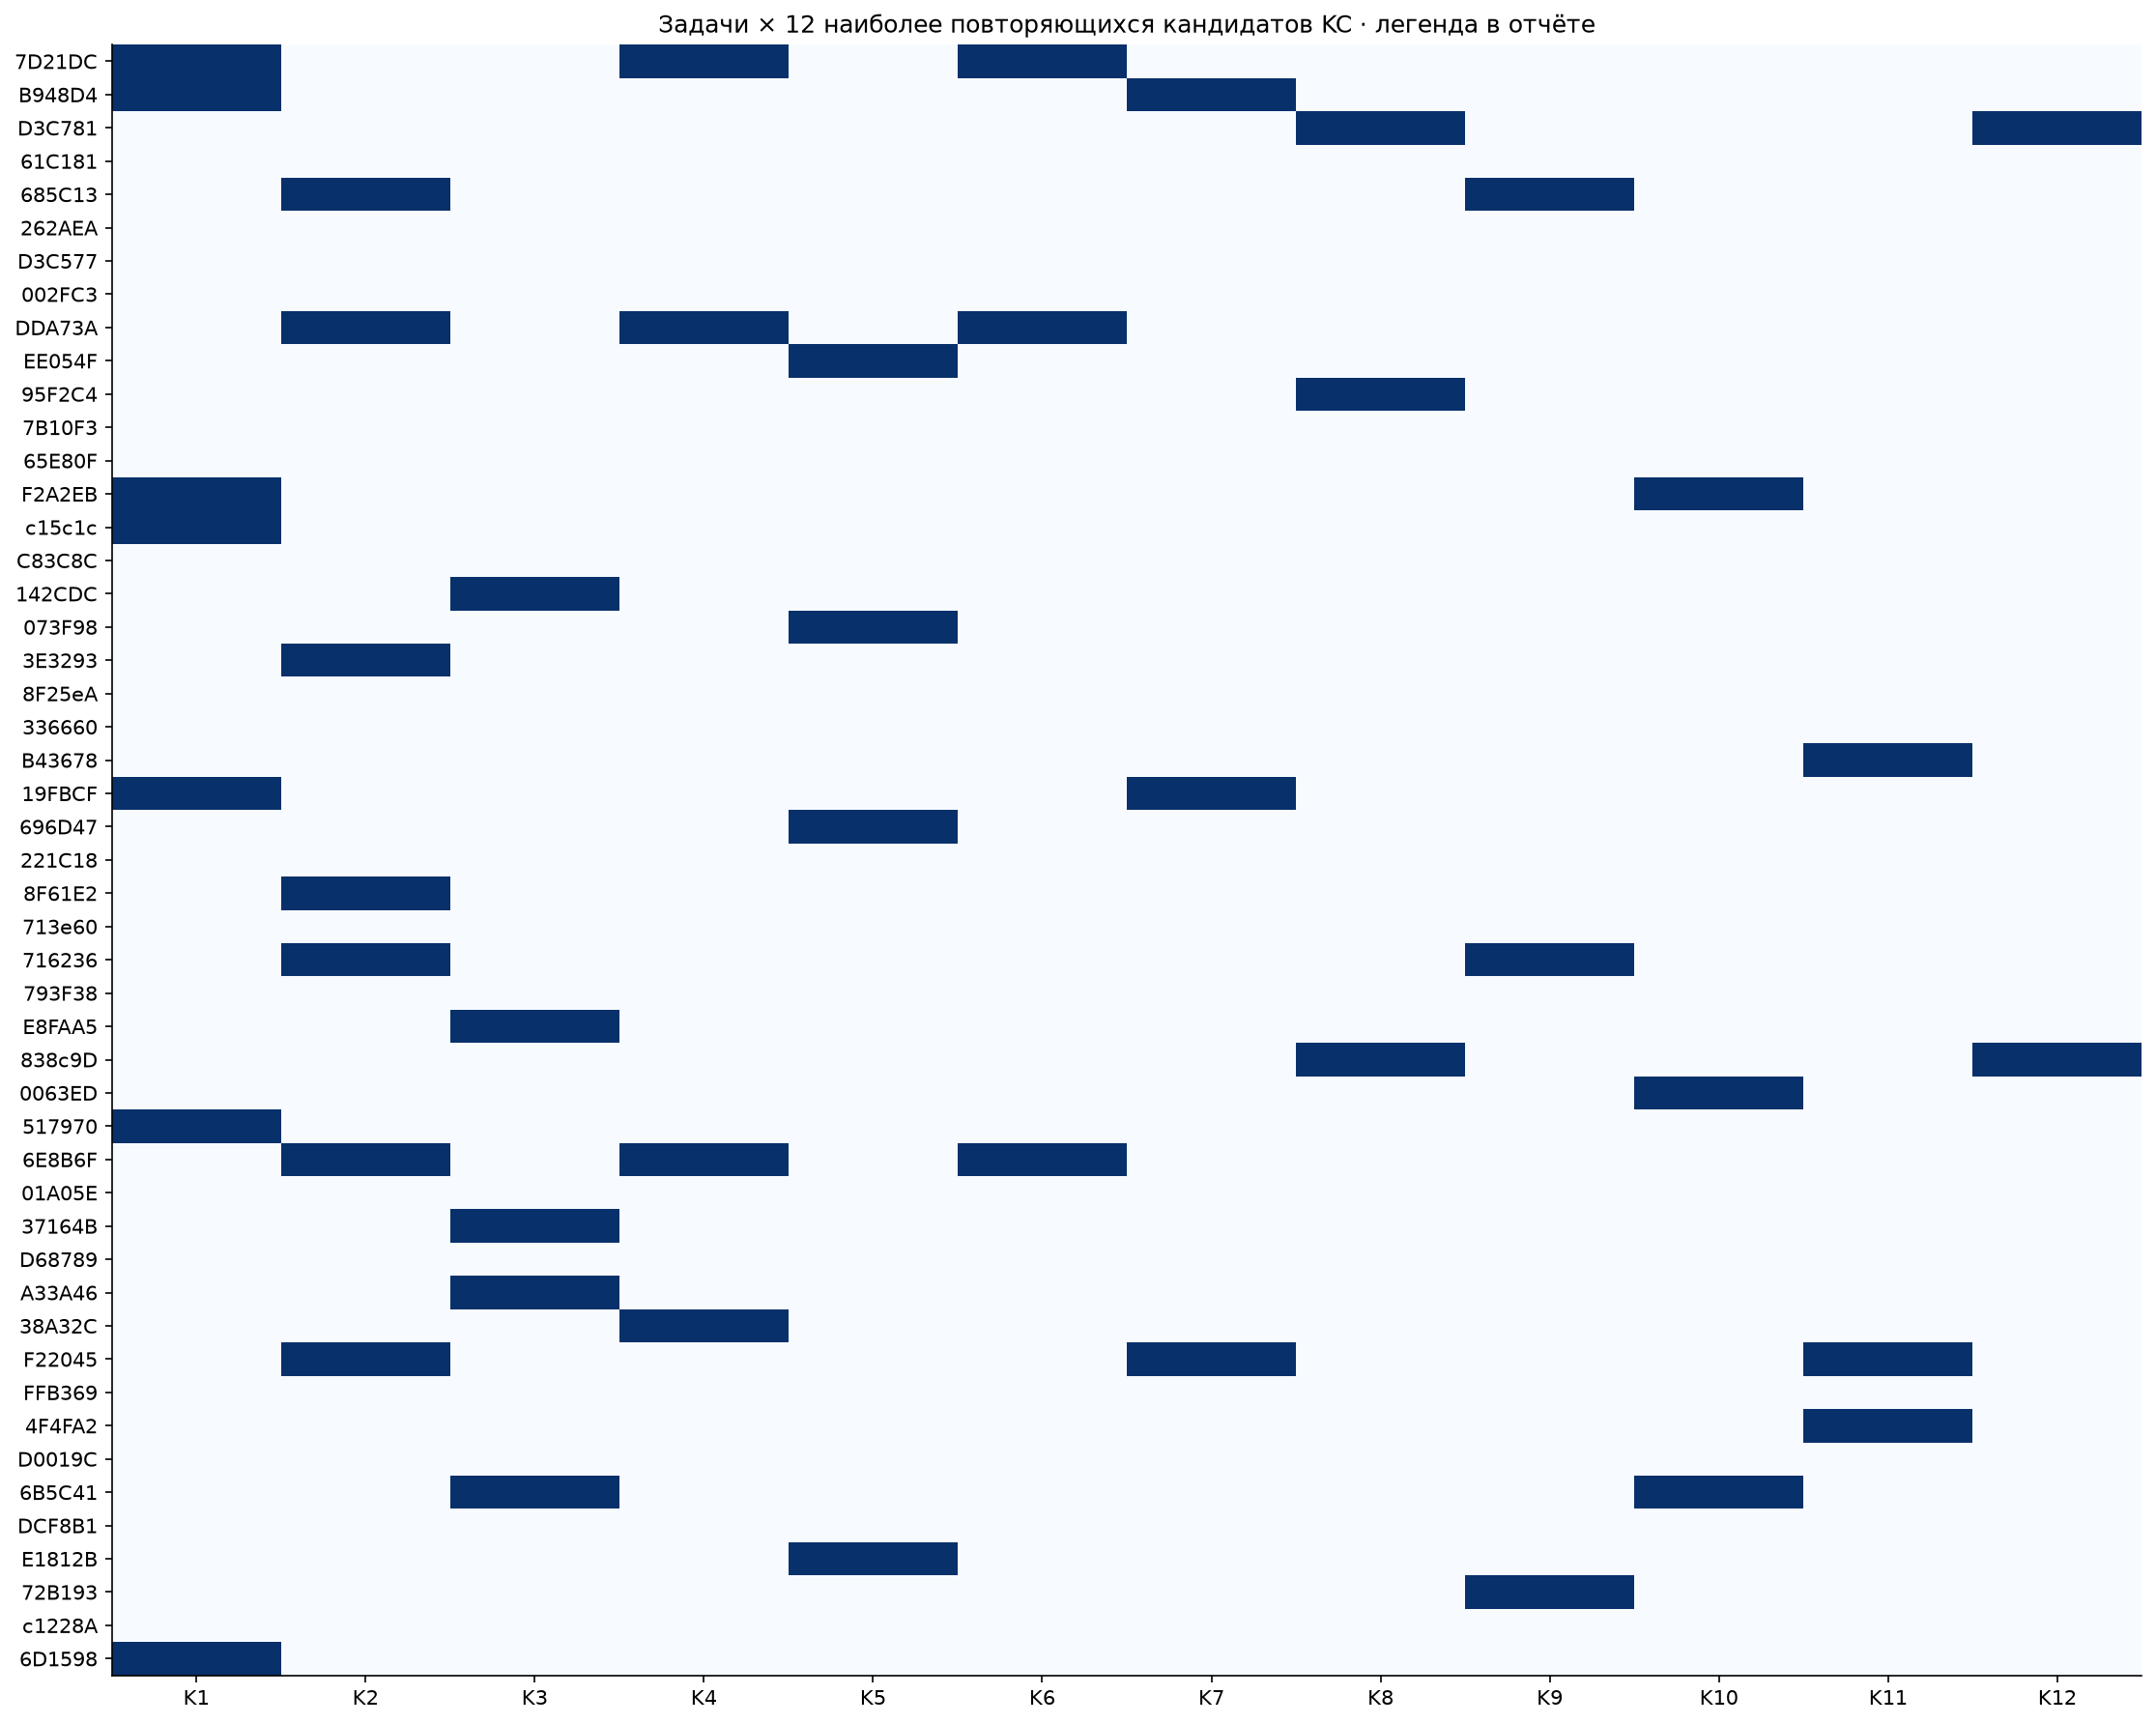

In [5]:
table([{'Показатель':k,'Значение':summary[k]} for k in ['literal_definition_nodes_included','editorial_nodes_included','singleton_nodes','singleton_fraction']])
table(rows('kc-frequencies.csv'), ['kc_id','name','task_n','task_pct'], limit=15)
display(Image(filename=str(OUT/'04-recurrent-kcs.png')))
display(Image(filename=str(OUT/'05-task-kc-matrix.png')))

**Вывод.** Решение линейного уравнения встречается после графической модели, снятия показателей и логарифма, в физической формуле, процентах и геометрии. Это даёт кандидатов для смены контекста практики одного действия. Однако перенос у ученика этим не измерен.

У большинства узлов пока один пример. Широкий охват, малый объём и неодинаковая детализация смешаны; не следует автоматически склеивать единичные узлы. Нужны просмотр определений и контрпримеры.

## 5. Совместная встречаемость и порядок

Пары считаются на уровне уникальных задач. Переходы — между соседними шагами внутри каждого использованного Method, с дедупликацией по задаче. Не соединяем независимые пункты искусственным порядком; внутри шага с несколькими KC порядок не известен.

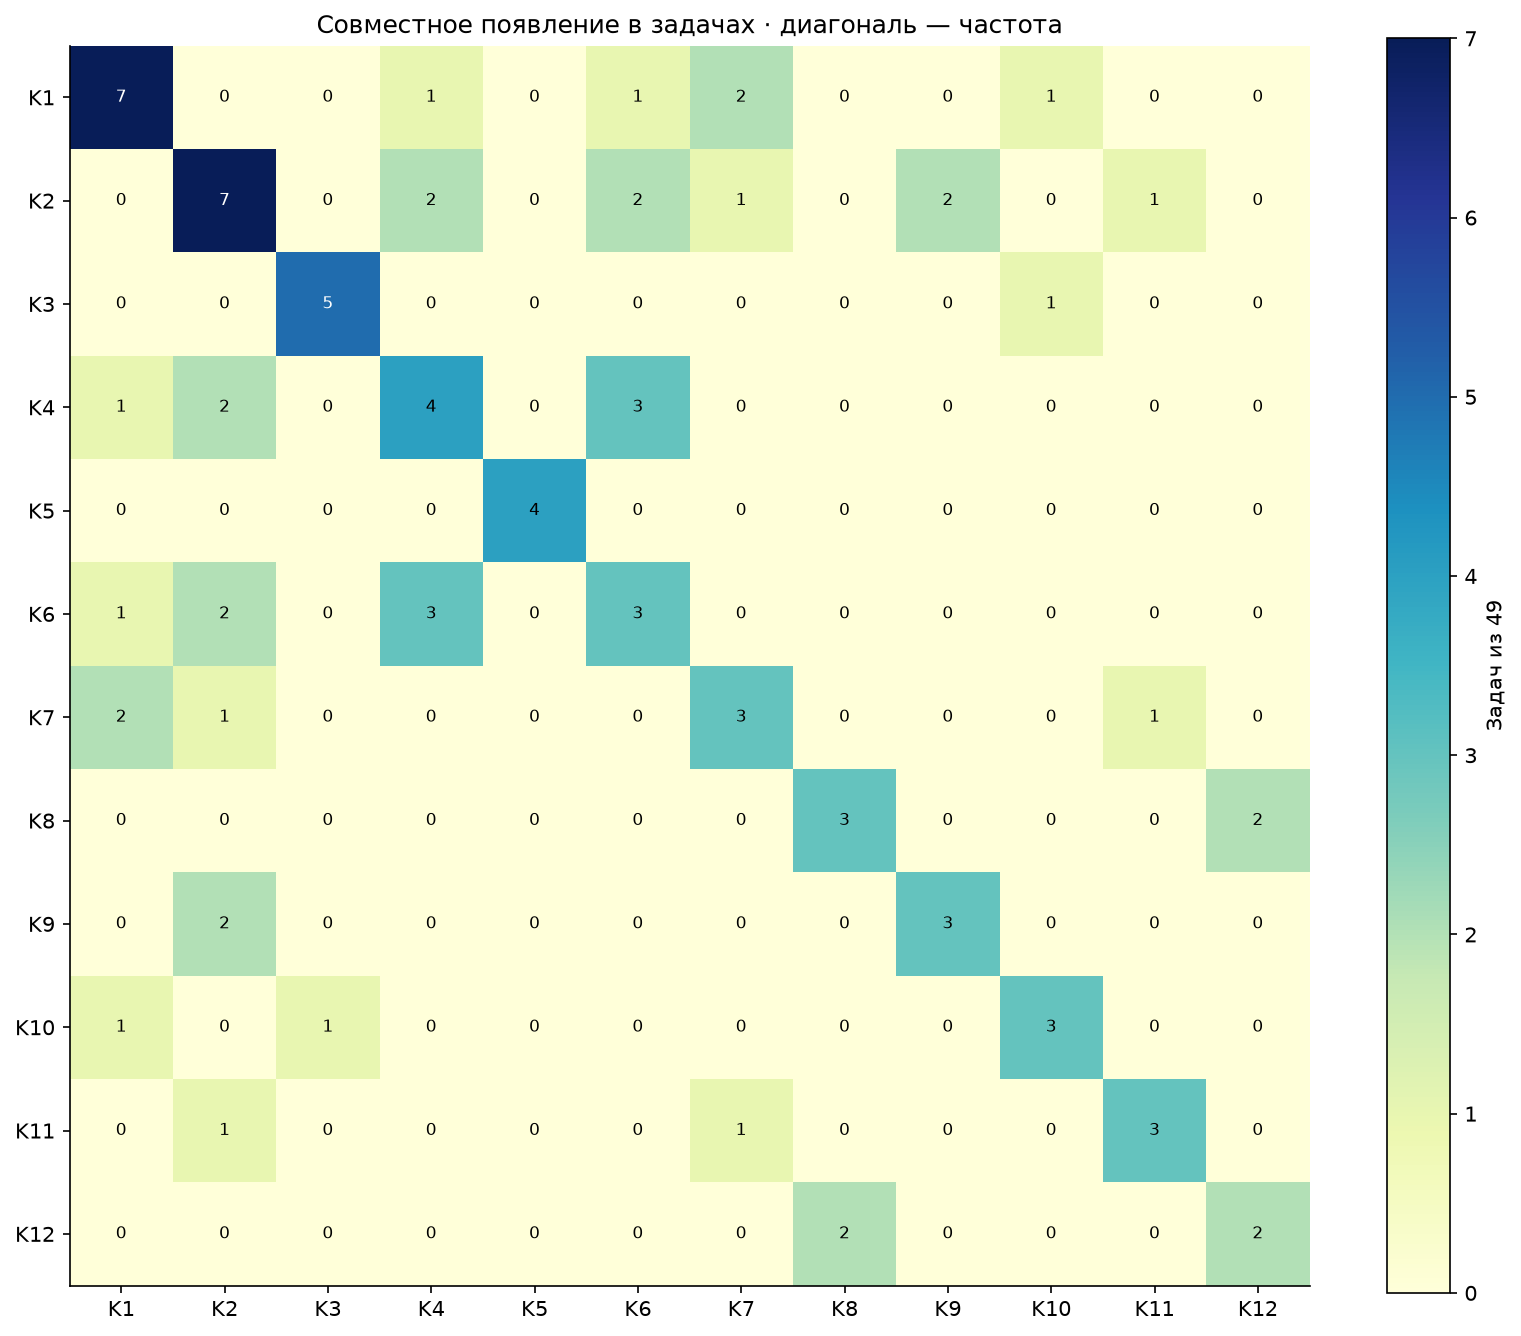

label,kc_id,name
K1,linear_equation,Решать линейное уравнение с числовыми коэффициентами
K2,zero_product,Решать уравнение через нулевое произведение
K3,pythagoras,Находить длину по теореме Пифагора
K4,graph_coordinates,Считывать координаты отмеченной точки с графика
K5,set_intersection,Пересекать множества допустимых значений
K6,graph_intersection,Сводить пересечение графиков к равенству значений
K7,exponential_equation,Сводить показательное уравнение к равенству показателей
K8,classical_probability,Вычислять вероятность по числу равновозможных исходов
K9,elementary_trig_equation,Решать простейшее тригонометрическое уравнение
K10,cosine_law,Применять теорему косинусов


Из,В,Задач
Сводить показательное уравнение к равенству показателей,Решать линейное уравнение с числовыми коэффициентами,2
Строить равновозможную модель случайного выбора,Вычислять вероятность по числу равновозможных исходов,2
Решать простейшее тригонометрическое уравнение,Отбирать периодические корни на заданном промежутке,2
Восстанавливать прямую пропорциональность по точке,Сводить пересечение графиков к равенству значений,2
Восстанавливать прямую пропорциональность по точке,Решать уравнение через нулевое произведение,2
Считывать координаты отмеченной точки с графика,Восстанавливать прямую пропорциональность по точке,2
Находить стационарные точки по нулю производной,Находить глобальный экстремум на отрезке,2
Считывать координаты отмеченной точки с графика,Восстанавливать линейную функцию по двум точкам,1
Сводить пересечение графиков к равенству значений,Решать линейное уравнение с числовыми коэффициентами,1
Восстанавливать линейную функцию по двум точкам,Сводить пересечение графиков к равенству значений,1


In [6]:
display(Image(filename=str(OUT/'06-cooccurrence.png')))
table(rows('cooccurrence-legend.csv'))
catalog = json.loads((RUN/'catalog-decisions.json').read_text(encoding='utf-8'))
names = {r['id']:r['name'] for r in catalog['nodes']}
table([{'Из':names[r['from_kc']],'В':names[r['to_kc']],'Задач':r['task_n']} for r in rows('kc-transitions.csv')[:10]])

**Вывод.** Сочетания и повторяющиеся переходы дают кандидатов на структуру упражнений и подсказок. Они не доказывают prerequisites и не требуют одинаковых списков KC у разных правильных методов.

## 6. Что просмотреть дальше

1. Неоднозначность `eFF32e`: внутреннее пересечение ребра и случай вершины.
2. Границы популярных узлов: линейное уравнение, чтение графика, нулевое произведение.
3. Единичные кандидаты: найти дополнительные подтверждения и контрпримеры, прежде чем менять каталог.
4. Отделить новую проверочную выборку, учитывая похожие числовые шаблоны.

Нет данных учеников, внешнего экспертного эталона и независимых повторов. Полезность тьютору остаётся проверяемой проектной гипотезой. Новых пакетов автоматически нет.

[Все 50 карточек и графики](../data/annotation/runs/2026-10-31-fipi-50x1/derived/index.html) · [Определения KC](../data/annotation/runs/2026-10-31-fipi-50x1/derived/catalog.html) · [Подробный отчёт](../data/annotation/runs/2026-10-31-fipi-50x1/derived/report.md)